1. Imports

In [3]:
import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt
import os
from glob import glob
from scipy import ndimage


 2. Paths

In [5]:
input_dir = "../Desktop/project - Copy/preprocessed/resampled"        # Your resampled scans
output_dir = "../Desktop/project - Copy/preprocessed/segmented_lungs"  # New folder for masks
os.makedirs(output_dir, exist_ok=True)

sample_scan = glob(f"{input_dir}/*.mhd")[0]  # Try one scan first


 3. Lung Segmentation Function

In [7]:
def segment_lungs(image, plot_steps=False):
    img_array = sitk.GetArrayFromImage(image)

    # Step 1: Thresholding
    binary_image = np.array(img_array < -320, dtype=np.int8)

    if plot_steps:
        plt.figure(figsize=(6,6))
        plt.imshow(binary_image[binary_image.shape[0]//2], cmap='gray')
        plt.title("Thresholded (< -320 HU)")
        plt.axis('off')
        plt.show()

    # Step 2: Morphological operations
    cleared = np.copy(binary_image)
    for i in range(cleared.shape[0]):
        cleared[i] = ndimage.binary_fill_holes(cleared[i])
        cleared[i] = ndimage.binary_erosion(cleared[i])

    if plot_steps:
        plt.figure(figsize=(6,6))
        plt.imshow(cleared[cleared.shape[0]//2], cmap='gray')
        plt.title("Border-cleared and Eroded")
        plt.axis('off')
        plt.show()

    # Step 3: Connected components
    label_array, num_features = ndimage.label(cleared)

    # Step 4: Keep the two largest components (lungs)
    sizes = ndimage.sum_labels(np.ones_like(label_array), label_array, index=range(1, num_features + 1))
    sorted_labels = np.argsort(sizes)[-2:] + 1
    lungs_mask = np.isin(label_array, sorted_labels).astype(np.uint8)

    if plot_steps:
        plt.figure(figsize=(6,6))
        plt.imshow(lungs_mask[lungs_mask.shape[0]//2], cmap='gray')
        plt.title("Final Lung Mask")
        plt.axis('off')
        plt.show()

    return lungs_mask


4. Visualization: Overlay Mask on CT Slice

In [9]:
def plot_mask_overlay(scan, mask):
    scan_array = sitk.GetArrayFromImage(scan)
    fig, axs = plt.subplots(1, 2, figsize=(12, 6))

    axs[0].imshow(scan_array[scan_array.shape[0]//2], cmap='gray')
    axs[0].set_title("Original CT Slice")
    axs[0].axis('off')

    axs[1].imshow(scan_array[scan_array.shape[0]//2], cmap='gray')
    axs[1].imshow(mask[mask.shape[0]//2], alpha=0.4, cmap='Reds')
    axs[1].set_title("Lung Mask Overlay")
    axs[1].axis('off')

    plt.tight_layout()
    plt.show()


5.Test on One Scan

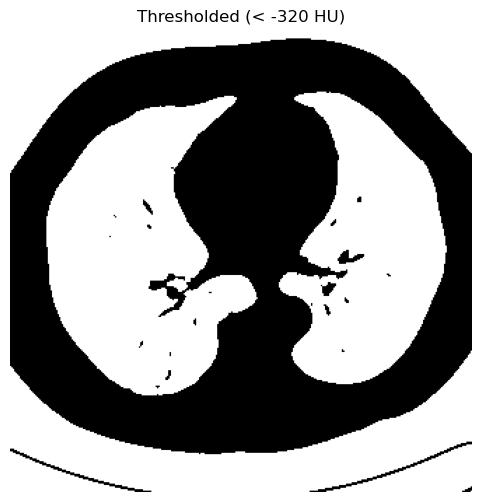

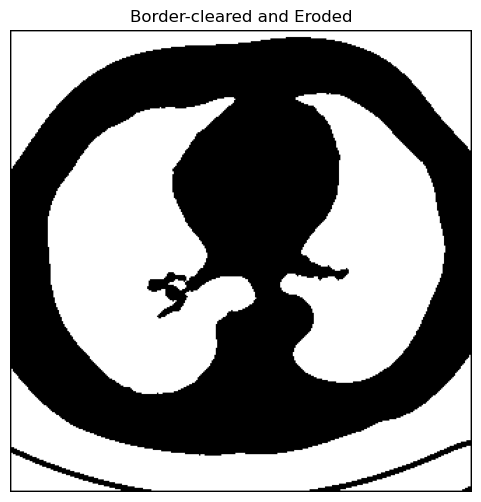

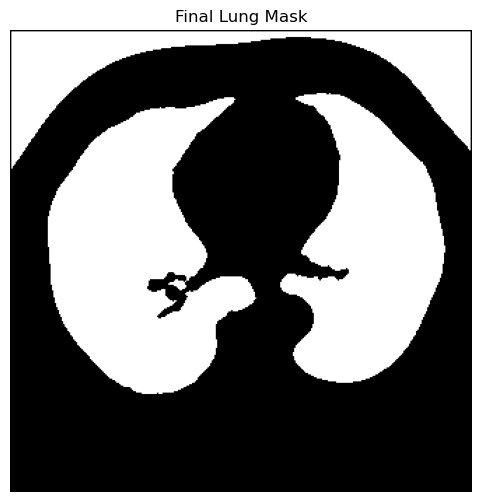

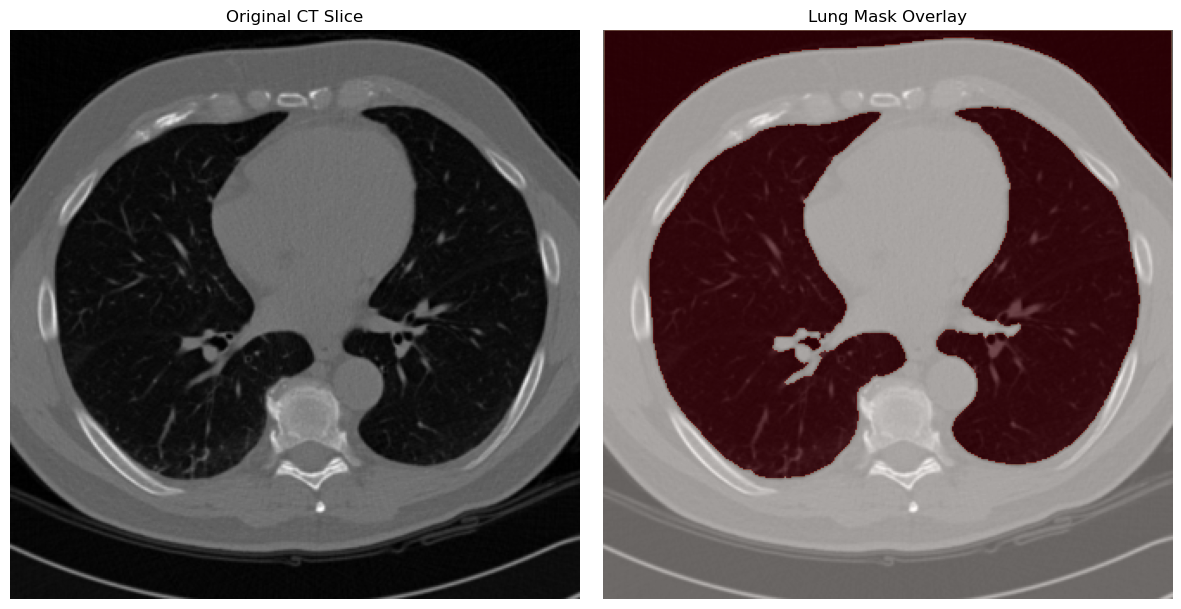

In [11]:
scan = sitk.ReadImage(sample_scan)
lung_mask = segment_lungs(scan, plot_steps=True)

plot_mask_overlay(scan, lung_mask)


6. Save the Lung Mask

In [15]:
# Save as compressed numpy file
uid = os.path.basename(sample_scan).replace("_resampled.mhd", "")
np.savez_compressed(os.path.join(output_dir, f"{uid}_lungmask.npz"), mask=lung_mask)


7. Process All Scans

In [17]:
all_scans = glob(f"{input_dir}/*.mhd")

for scan_path in all_scans:
    print(f"Segmenting lungs for: {scan_path}")
    scan = sitk.ReadImage(scan_path)
    lung_mask = segment_lungs(scan)

    uid = os.path.basename(scan_path).replace("_resampled.mhd", "")
    np.savez_compressed(os.path.join(output_dir, f"{uid}_lungmask.npz"), mask=lung_mask)


Segmenting lungs for: ../Desktop/project - Copy/preprocessed/resampled\1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222365663678666836860_resampled.mhd
Segmenting lungs for: ../Desktop/project - Copy/preprocessed/resampled\1.3.6.1.4.1.14519.5.2.1.6279.6001.100332161840553388986847034053_resampled.mhd
Segmenting lungs for: ../Desktop/project - Copy/preprocessed/resampled\1.3.6.1.4.1.14519.5.2.1.6279.6001.100398138793540579077826395208_resampled.mhd
Segmenting lungs for: ../Desktop/project - Copy/preprocessed/resampled\1.3.6.1.4.1.14519.5.2.1.6279.6001.100530488926682752765845212286_resampled.mhd
Segmenting lungs for: ../Desktop/project - Copy/preprocessed/resampled\1.3.6.1.4.1.14519.5.2.1.6279.6001.100620385482151095585000946543_resampled.mhd
Segmenting lungs for: ../Desktop/project - Copy/preprocessed/resampled\1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016233746780170740405_resampled.mhd
Segmenting lungs for: ../Desktop/project - Copy/preprocessed/resampled\1.3.6.1.4.1.14519.5.2.1.6279.

In [19]:
import random

def visualize_random_segmentations(num_samples=5):
    mask_files = glob(f"{output_dir}/*.npz")
    
    if num_samples > len(mask_files):
        num_samples = len(mask_files)
    
    selected = random.sample(mask_files, num_samples)
    
    for mask_path in selected:
        uid = os.path.basename(mask_path).replace("_lungmask.npz", "")
        scan_path = os.path.join(input_dir, f"{uid}_resampled.mhd")
        
        if not os.path.exists(scan_path):
            print(f"⚠️ Missing scan for {uid}")
            continue
        
        scan = sitk.ReadImage(scan_path)
        scan_array = sitk.GetArrayFromImage(scan)
        
        mask = np.load(mask_path)['mask']
        
        fig, axs = plt.subplots(1, 2, figsize=(12, 6))

        axs[0].imshow(scan_array[scan_array.shape[0]//2], cmap='gray')
        axs[0].set_title(f"Original CT Slice ({uid})")
        axs[0].axis('off')

        axs[1].imshow(scan_array[scan_array.shape[0]//2], cmap='gray')
        axs[1].imshow(mask[mask.shape[0]//2], alpha=0.4, cmap='Reds')
        axs[1].set_title(f"Lung Mask Overlay ({uid})")
        axs[1].axis('off')

        plt.tight_layout()
        plt.show()


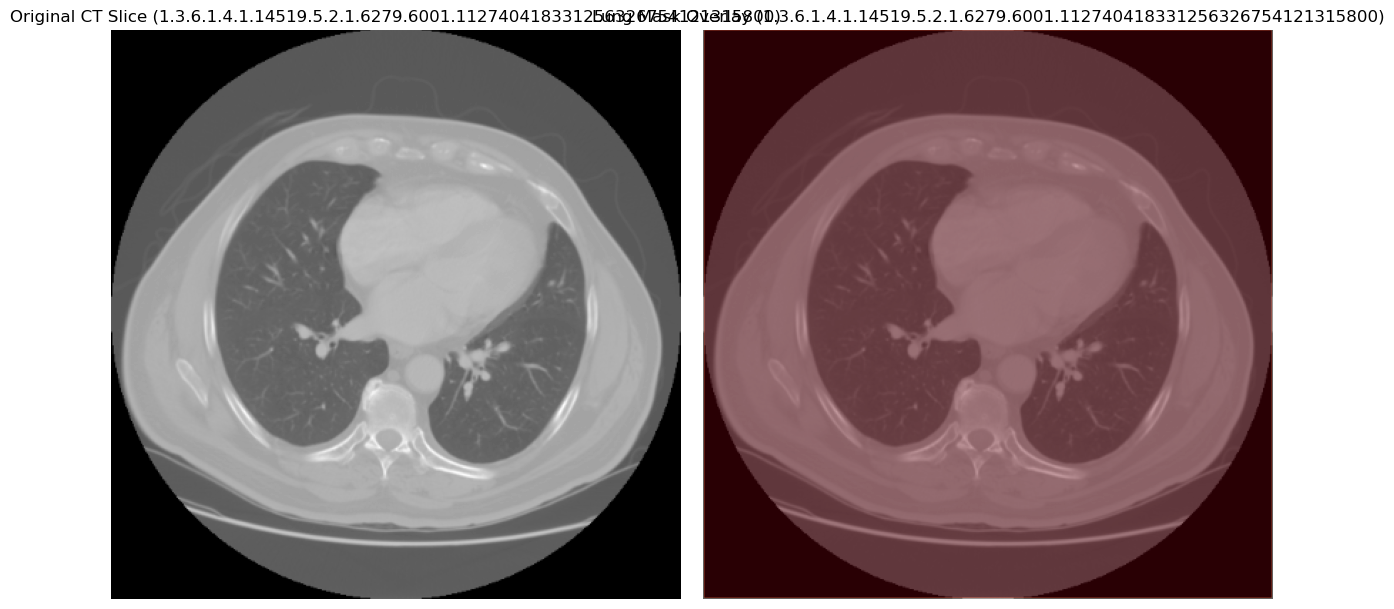

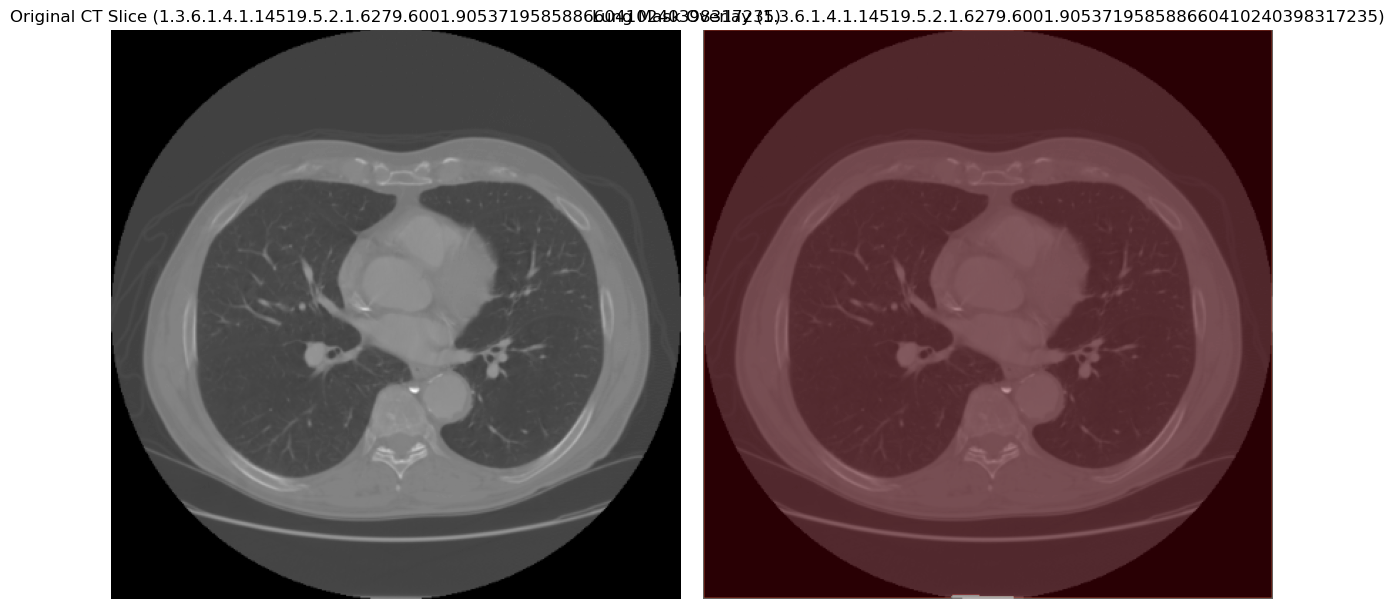

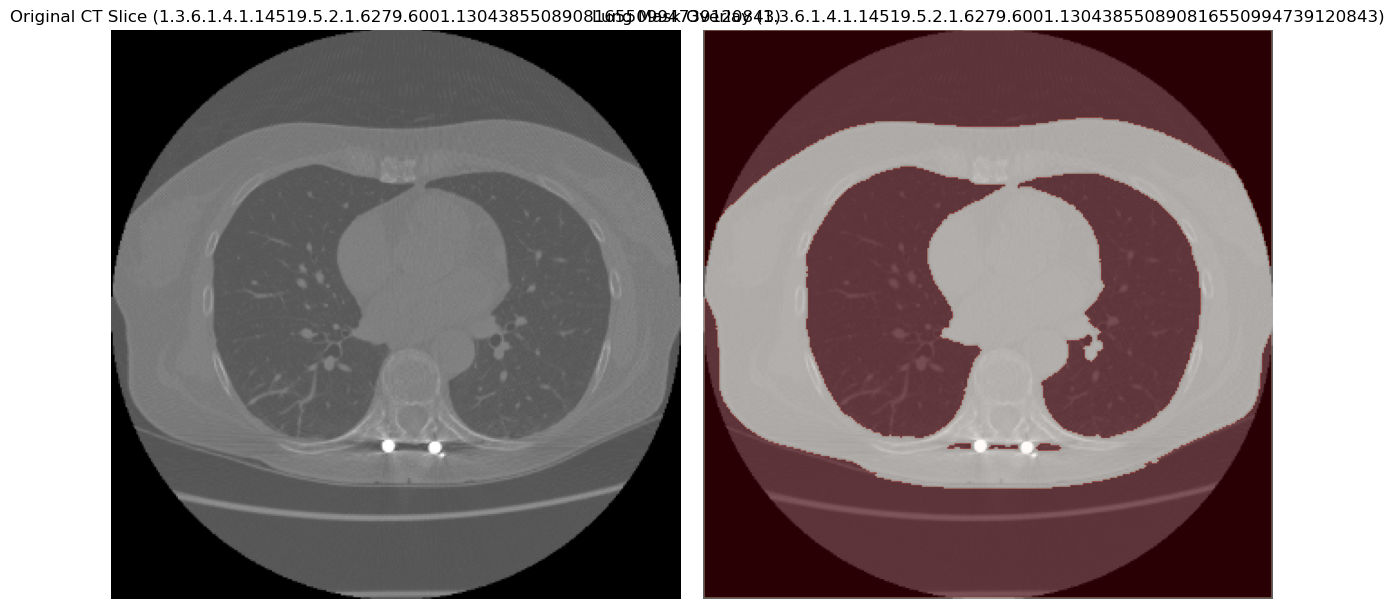

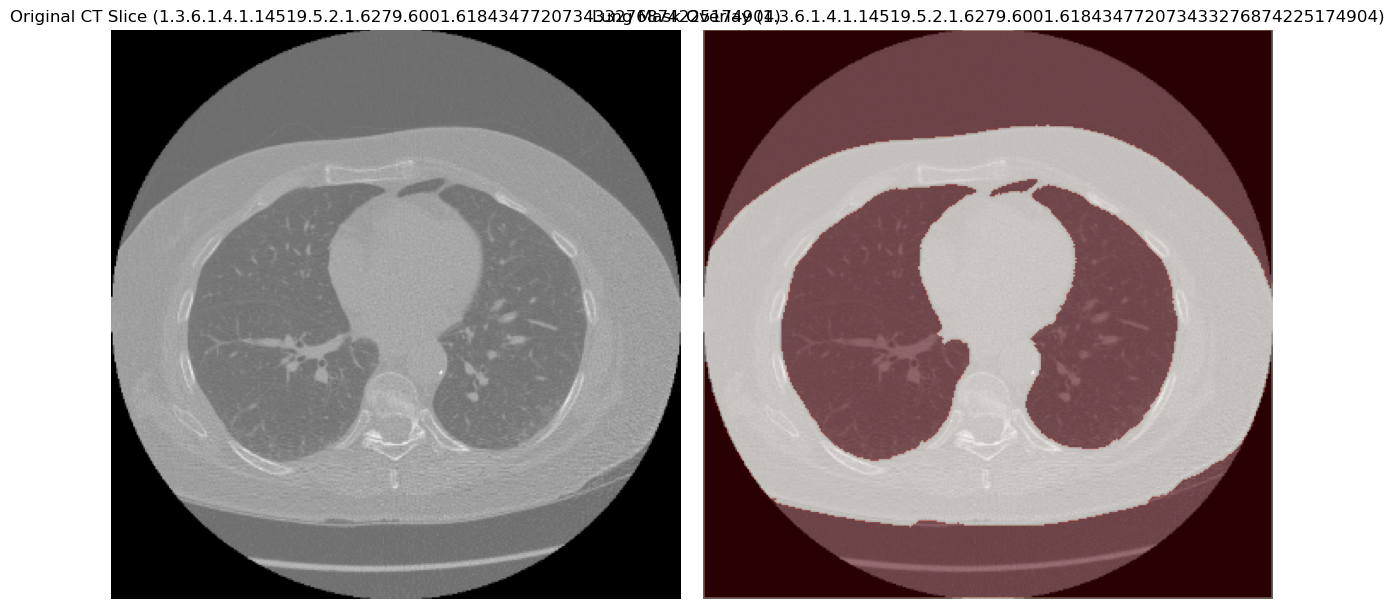

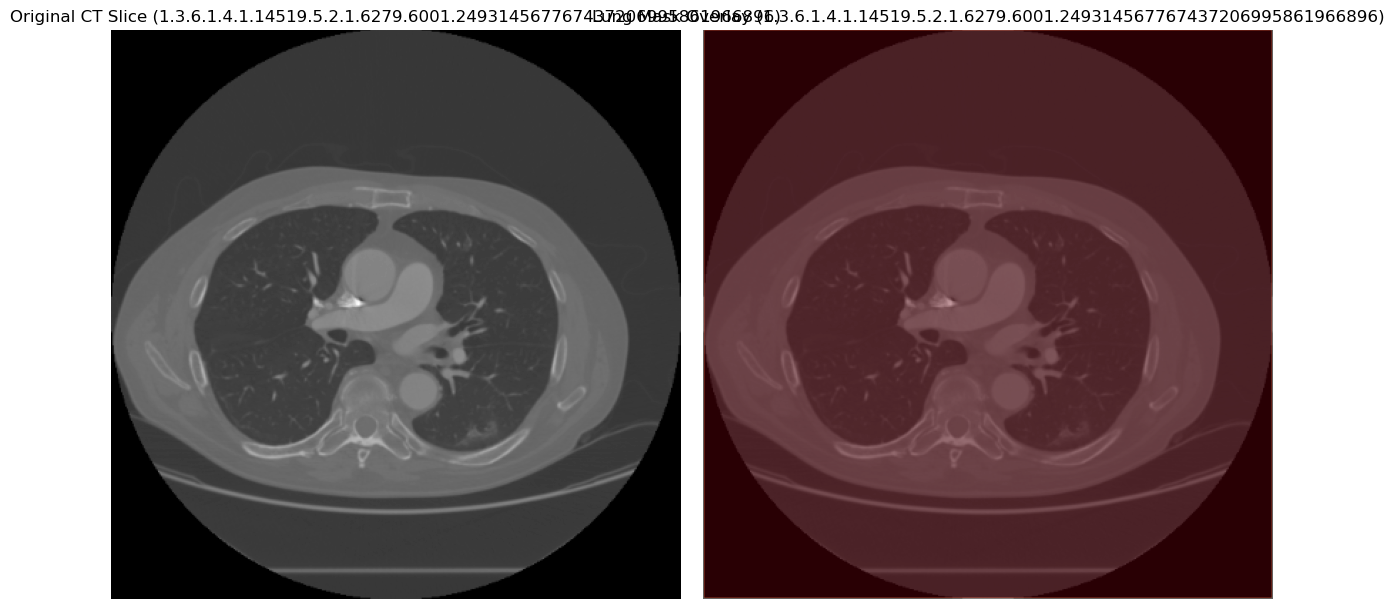

In [21]:
visualize_random_segmentations(num_samples=5)
